# 実験2 (ex002): 過学習抑制と拡張解析特徴量による改善実験

実験1（`ex001`）で再現された論文モデルの2大課題：
1. 盤面テンソルの高次元性（71,680次元 / 37,888次元）による深刻な過学習
2. Stockfish 評価値・残り持ち時間の未正規化およびブランチ間の重み・表現力不均衡
を解決するため，以下の改善手法を導入して効果を検証する．

### 改善アプローチ
- **6次元拡張解析特徴量**: `tanh(eval/4)`, **Centipawn Loss (CPL)**, `|Δeval|`, 残り時間割合 `clk/init`, 消費時間 `log1p(Δt)`, 手番フラグ
- **リーク防止標準化**: 訓練データ有効手のみから平均・標準偏差を算出し Z-score 標準化
- **アーキテクチャ・正則化改善**: `BatchNorm`・`AdaptiveAvgPool3d` 圧縮・`Dropout` 強化・`AdamW`・`CosineAnnealingLR`・`Label Smoothing`
- **アブレーション比較**: `Analyzed-Only MLP`, `Temporal ConvNet`, `Improved Analyzed Dense`, `Improved Analyzed CNN`

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / 'datasets').exists() else cwd.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ex002.model import build_improved_model
from ex002.utils import (
    compute_channel_ablation_importance,
    create_dataloaders,
    load_and_split_dataset,
    plot_confusion_matrices,
    plot_ex001_vs_ex002_comparison,
    plot_extended_feature_distributions,
    plot_feature_importance,
    plot_improved_learning_curves,
    set_seed,
    standardize_extended_features,
    summarize_results,
    train_and_evaluate_improved,
)

SEED = 42
set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'使用デバイス: {device}')

使用デバイス: cuda


C:\Users\watasaku\.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at C:\Users\watasaku\AppData\Local\Temp\matplotlib-5sbpyz_w because there was an issue with the default path (C:\Users\watasaku\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


=== チーター手番 vs 非チーター手番 拡張特徴量統計 ===


,Group,Plies,Mean CPL (pawn),Median CPL (pawn),Zero-Loss Ratio (%),Mean Think Time (s),Std Think Time (s),Mean |Δeval| (pawn)
0,非チーター手番 (Human),234781,0.781,0.2,35.481,4.158,5.796,0.849
1,チーター手番 (Cheater),76227,0.785,0.2,35.962,4.355,6.277,0.858


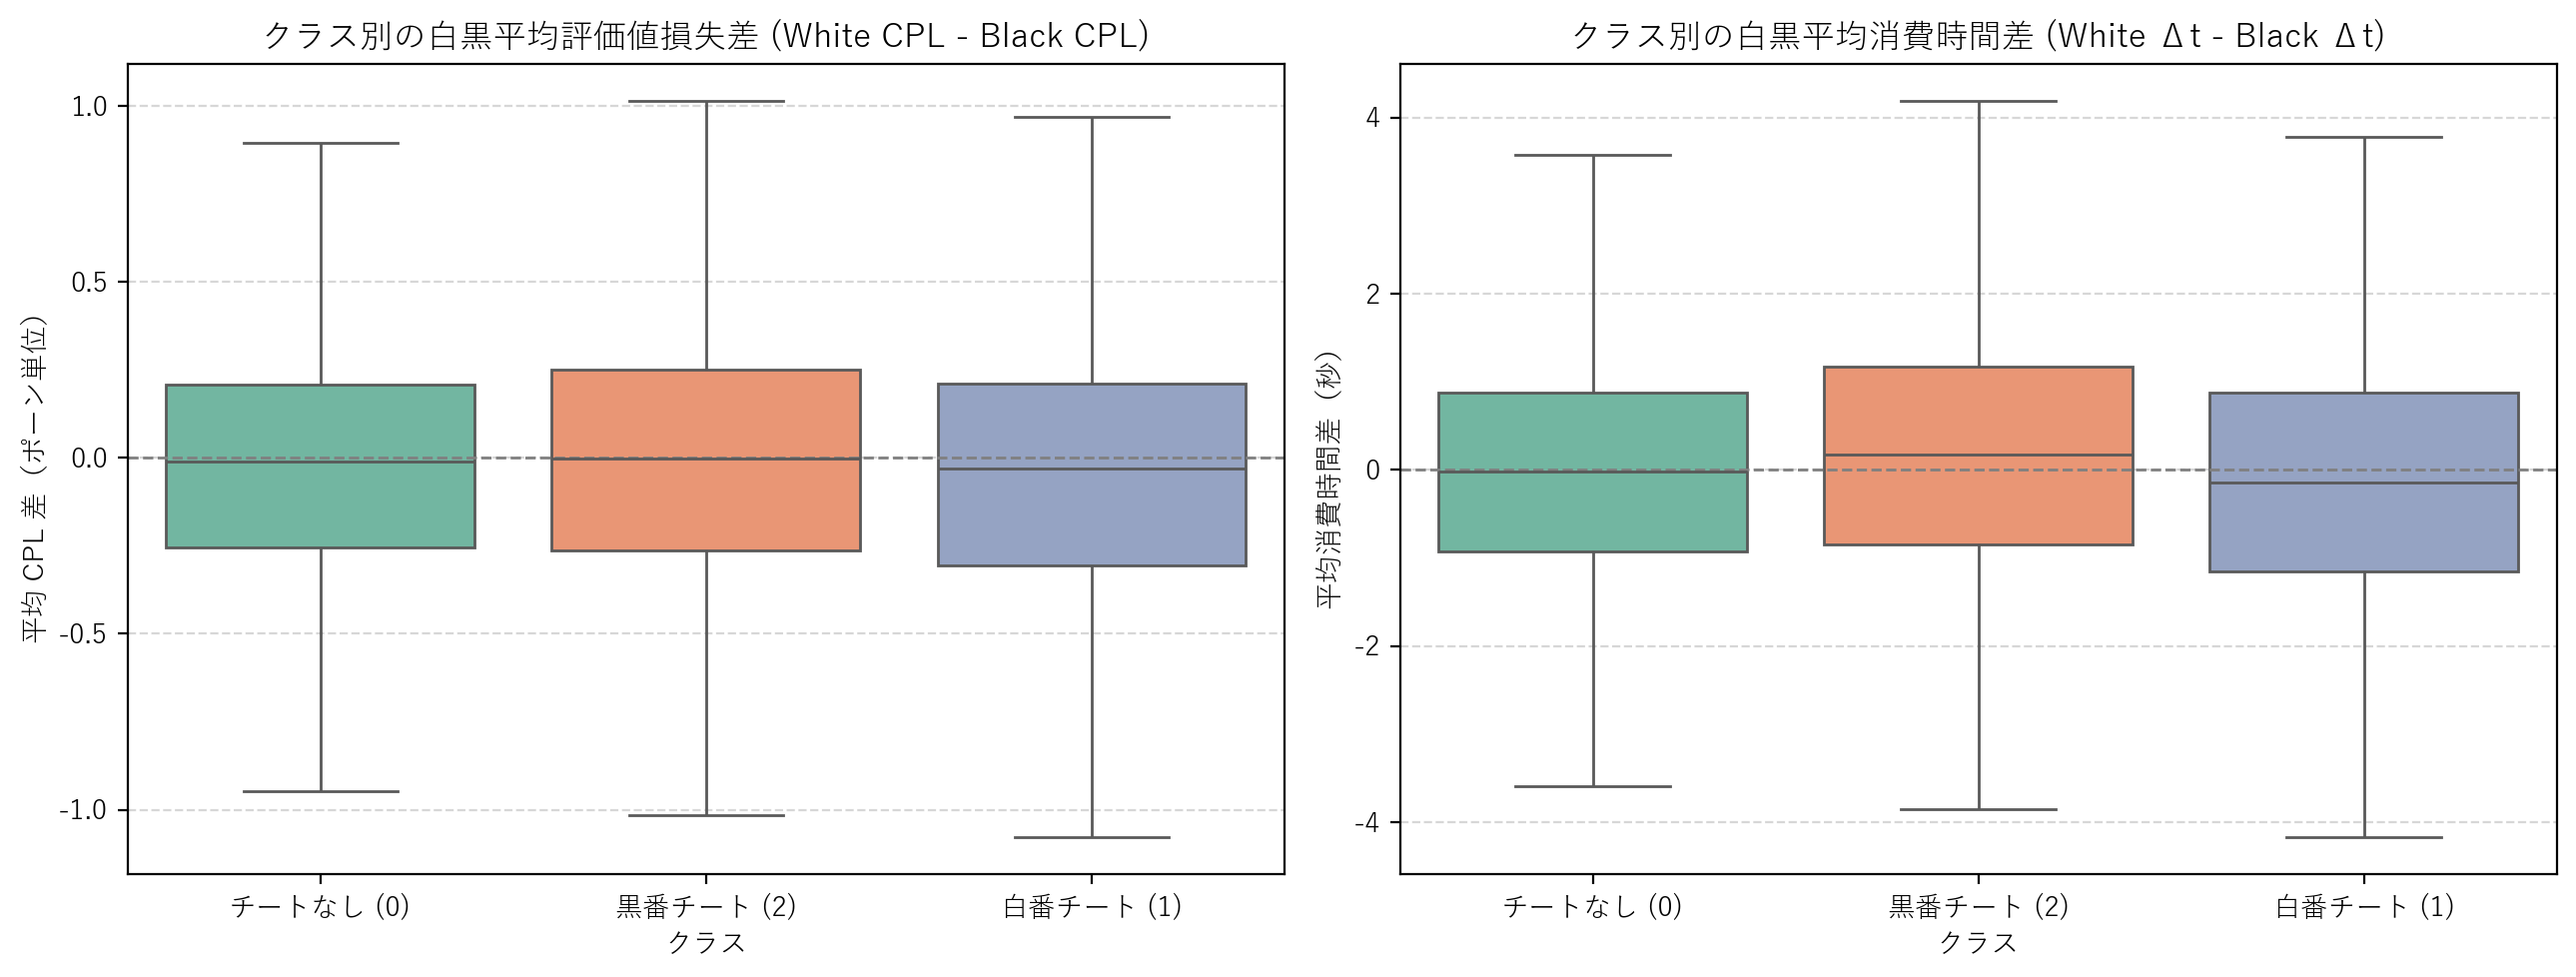

In [2]:
npz_path = PROJECT_ROOT / 'datasets' / 'chess_cheat_dataset.npz'
raw_data = np.load(npz_path)
img_dir = PROJECT_ROOT / 'report' / 'img'

stats_df = plot_extended_feature_distributions(
    x_board=raw_data['X_board'],
    x_analyzed_ext=raw_data['X_analyzed_ext'],
    y=raw_data['y'],
    save_path=img_dir / 'ex002_feature_distributions.png',
)
print('=== チーター手番 vs 非チーター手番 拡張特徴量統計 ===')
display(stats_df.round(3))
display(Image(filename=str(img_dir / 'ex002_feature_distributions.png')))

In [3]:
splits_raw = load_and_split_dataset(npz_path, seed=SEED, use_extended_analyzed=True)
splits, feat_mean, feat_std = standardize_extended_features(splits_raw)
print('拡張特徴量平均 (Train):', np.round(feat_mean, 4))
print('拡張特徴量標準偏差 (Train):', np.round(feat_std, 4))

# 過学習抑制と安定した収束のためバッチ数は 1epoch あたり 30バッチ（batch_size=120）に設定
train_loader, val_loader, test_loader = create_dataloaders(
    splits, train_batches_per_epoch=30, eval_batch_size=200
)
print(f'Train batch_size: {train_loader.batch_size}, batches/epoch: {len(train_loader)}')

拡張特徴量平均 (Train): [0.0442 0.779  0.8476 0.7093 1.2795 0.0055]
拡張特徴量標準偏差 (Train): [0.5849 1.5722 1.5765 0.2662 0.8219 1.    ]
Train batch_size: 120, batches/epoch: 30


In [4]:
model_names = [
    'Analyzed-Only MLP',
    'Temporal ConvNet',
    'Improved Analyzed Dense',
    'Improved Analyzed CNN',
]

results = []
for name in model_names:
    set_seed(SEED)
    model = build_improved_model(name, num_classes=3, num_analyzed_features=6)
    res = train_and_evaluate_improved(
        model=model,
        model_name=name,
        train_loader=train_loader,
        val_loader=val_loader,
        test_loader=test_loader,
        device=device,
        epochs=25,
        lr=0.001,
        weight_decay=1e-4,
        label_smoothing=0.05,
    )
    results.append(res)
    print(f'--- {name} テスト評価結果 ---')
    print(
        f'Best Val: {res["best_val_acc"]*100:.2f}% | '
        f'Test Acc: {res["test_acc"]*100:.2f}% | '
        f'Macro F1: {res["f1_macro"]*100:.2f}% | '
        f'Time: {res["elapsed_sec"]:.2f}s'
    )
    display(pd.DataFrame(res['classification_report']).T.round(4))
    torch.cuda.empty_cache()

--- Analyzed-Only MLP テスト評価結果 ---
Best Val: 51.25% | Test Acc: 49.10% | Macro F1: 27.23% | Time: 21.97s
--- Temporal ConvNet テスト評価結果 ---
Best Val: 53.75% | Test Acc: 48.50% | Macro F1: 33.16% | Time: 23.04s
--- Improved Analyzed Dense テスト評価結果 ---
Best Val: 51.75% | Test Acc: 49.60% | Macro F1: 32.58% | Time: 20.41s
--- Improved Analyzed CNN テスト評価結果 ---
Best Val: 51.50% | Test Acc: 50.20% | Macro F1: 29.99% | Time: 23.07s


[Improved Analyzed CNN]: 100%|##########| 25/25 [00:23<00:00,  1.08it/s, best_val=0.5150, train_acc=0.6175, val_acc=0.4700]


,precision,recall,f1-score,support
Nobody cheats,0.5049,0.9360,0.6559,500.000
White cheats,0.3939,0.0520,0.0919,250.000
Black cheats,0.2500,0.0400,0.0690,250.000
accuracy,0.4910,0.4910,0.4910,0.491
macro avg,0.3829,0.3427,0.2723,1000.000
weighted avg,0.4134,0.4910,0.3682,1000.000


,precision,recall,f1-score,support
Nobody cheats,0.5221,0.8500,0.6469,500.000
White cheats,0.3205,0.1000,0.1524,250.000
Black cheats,0.3241,0.1400,0.1955,250.000
accuracy,0.4850,0.4850,0.4850,0.485
macro avg,0.3889,0.3633,0.3316,1000.000
weighted avg,0.4222,0.4850,0.4104,1000.000


,precision,recall,f1-score,support
Nobody cheats,0.5207,0.880,0.6543,500.000
White cheats,0.3939,0.052,0.0919,250.000
Black cheats,0.3525,0.172,0.2312,250.000
accuracy,0.4960,0.496,0.4960,0.496
macro avg,0.4224,0.368,0.3258,1000.000
weighted avg,0.4470,0.496,0.4079,1000.000


,precision,recall,f1-score,support
Nobody cheats,0.5149,0.934,0.6638,500.000
White cheats,0.4468,0.084,0.1414,250.000
Black cheats,0.3043,0.056,0.0946,250.000
accuracy,0.5020,0.502,0.5020,0.502
macro avg,0.4220,0.358,0.2999,1000.000
weighted avg,0.4452,0.502,0.3909,1000.000


In [5]:
summary_ex002 = summarize_results(results)
summary_ex002.to_csv(PROJECT_ROOT / 'ex002' / 'results_summary.csv', index=False, encoding='utf-8')
print('=== ex002 モデル性能サマリ ===')
display(summary_ex002.round(2))

# ex001 の結果と統合比較
ex001_csv = PROJECT_ROOT / 'ex001' / 'results_summary.csv'
if ex001_csv.exists():
    summary_ex001 = pd.read_csv(ex001_csv)
    summary_ex001['Experiment'] = 'ex001 (論文再現)'
else:
    summary_ex001 = pd.DataFrame()
s2 = summary_ex002.copy()
s2['Experiment'] = 'ex002 (改善実験)'
combined_df = pd.concat([summary_ex001, s2], ignore_index=True)
display(combined_df[['Experiment', 'Model', 'Params', 'Final Train Acc (%)', 'Best Val Acc (%)', 'Test Acc (%)', 'Macro F1 (%)', 'Train-Val Gap (%pt)']].round(2))

plot_improved_learning_curves(results, img_dir / 'ex002_learning_curves.png')
plot_ex001_vs_ex002_comparison(combined_df, img_dir / 'ex002_vs_ex001_comparison.png')
plot_confusion_matrices(results, img_dir / 'ex002_confusion_matrices.png')

=== ex002 モデル性能サマリ ===


,Model,Params,Final Train Acc (%),Best Val Acc (%),Final Val Acc (%),Test Acc (%),Macro F1 (%),Train-Val Gap (%pt),Time (s)
0,Analyzed-Only MLP,223491,83.00,51.25,46.0,49.1,27.23,37.00,21.97
1,Temporal ConvNet,130051,57.19,53.75,52.0,48.5,33.16,5.19,23.04
2,Improved Analyzed Dense,18603459,98.67,51.75,45.0,49.6,32.58,53.67,20.41
3,Improved Analyzed CNN,464803,61.75,51.50,47.0,50.2,29.99,14.75,23.07


,Experiment,Model,Params,Final Train Acc (%),Best Val Acc (%),Test Acc (%),Macro F1 (%),Train-Val Gap (%pt)
0,ex001 (論文再現),Unanalyzed Dense,36848643,99.92,50.75,41.7,36.00,53.42
1,ex001 (論文再現),Unanalyzed CNN,1501347,50.11,51.00,49.8,24.31,0.61
2,ex001 (論文再現),Analyzed Dense,37226755,99.67,50.50,43.5,35.94,52.67
3,ex001 (論文再現),Analyzed CNN,1879459,50.06,50.00,50.0,22.22,0.06
4,ex002 (改善実験),Analyzed-Only MLP,223491,83.00,51.25,49.1,27.23,37.00
5,ex002 (改善実験),Temporal ConvNet,130051,57.19,53.75,48.5,33.16,5.19
6,ex002 (改善実験),Improved Analyzed Dense,18603459,98.67,51.75,49.6,32.58,53.67
7,ex002 (改善実験),Improved Analyzed CNN,464803,61.75,51.50,50.2,29.99,14.75


最良モデル: Improved Analyzed CNN (Test Acc: 50.20%)


,Feature,Base Acc (%),Masked Acc (%),Acc Drop (%pt)
0,残り時間割合 (clk/init),50.2,49.6,0.6
1,消費時間 (log Δt),50.2,49.8,0.4
2,手番フラグ (White/Black),50.2,50.4,-0.2
3,評価値 (tanh圧縮),50.2,50.5,-0.3
4,評価値変動幅 (|Δeval|),50.2,51.2,-1.0
5,評価値損失 (CPL),50.2,51.6,-1.4


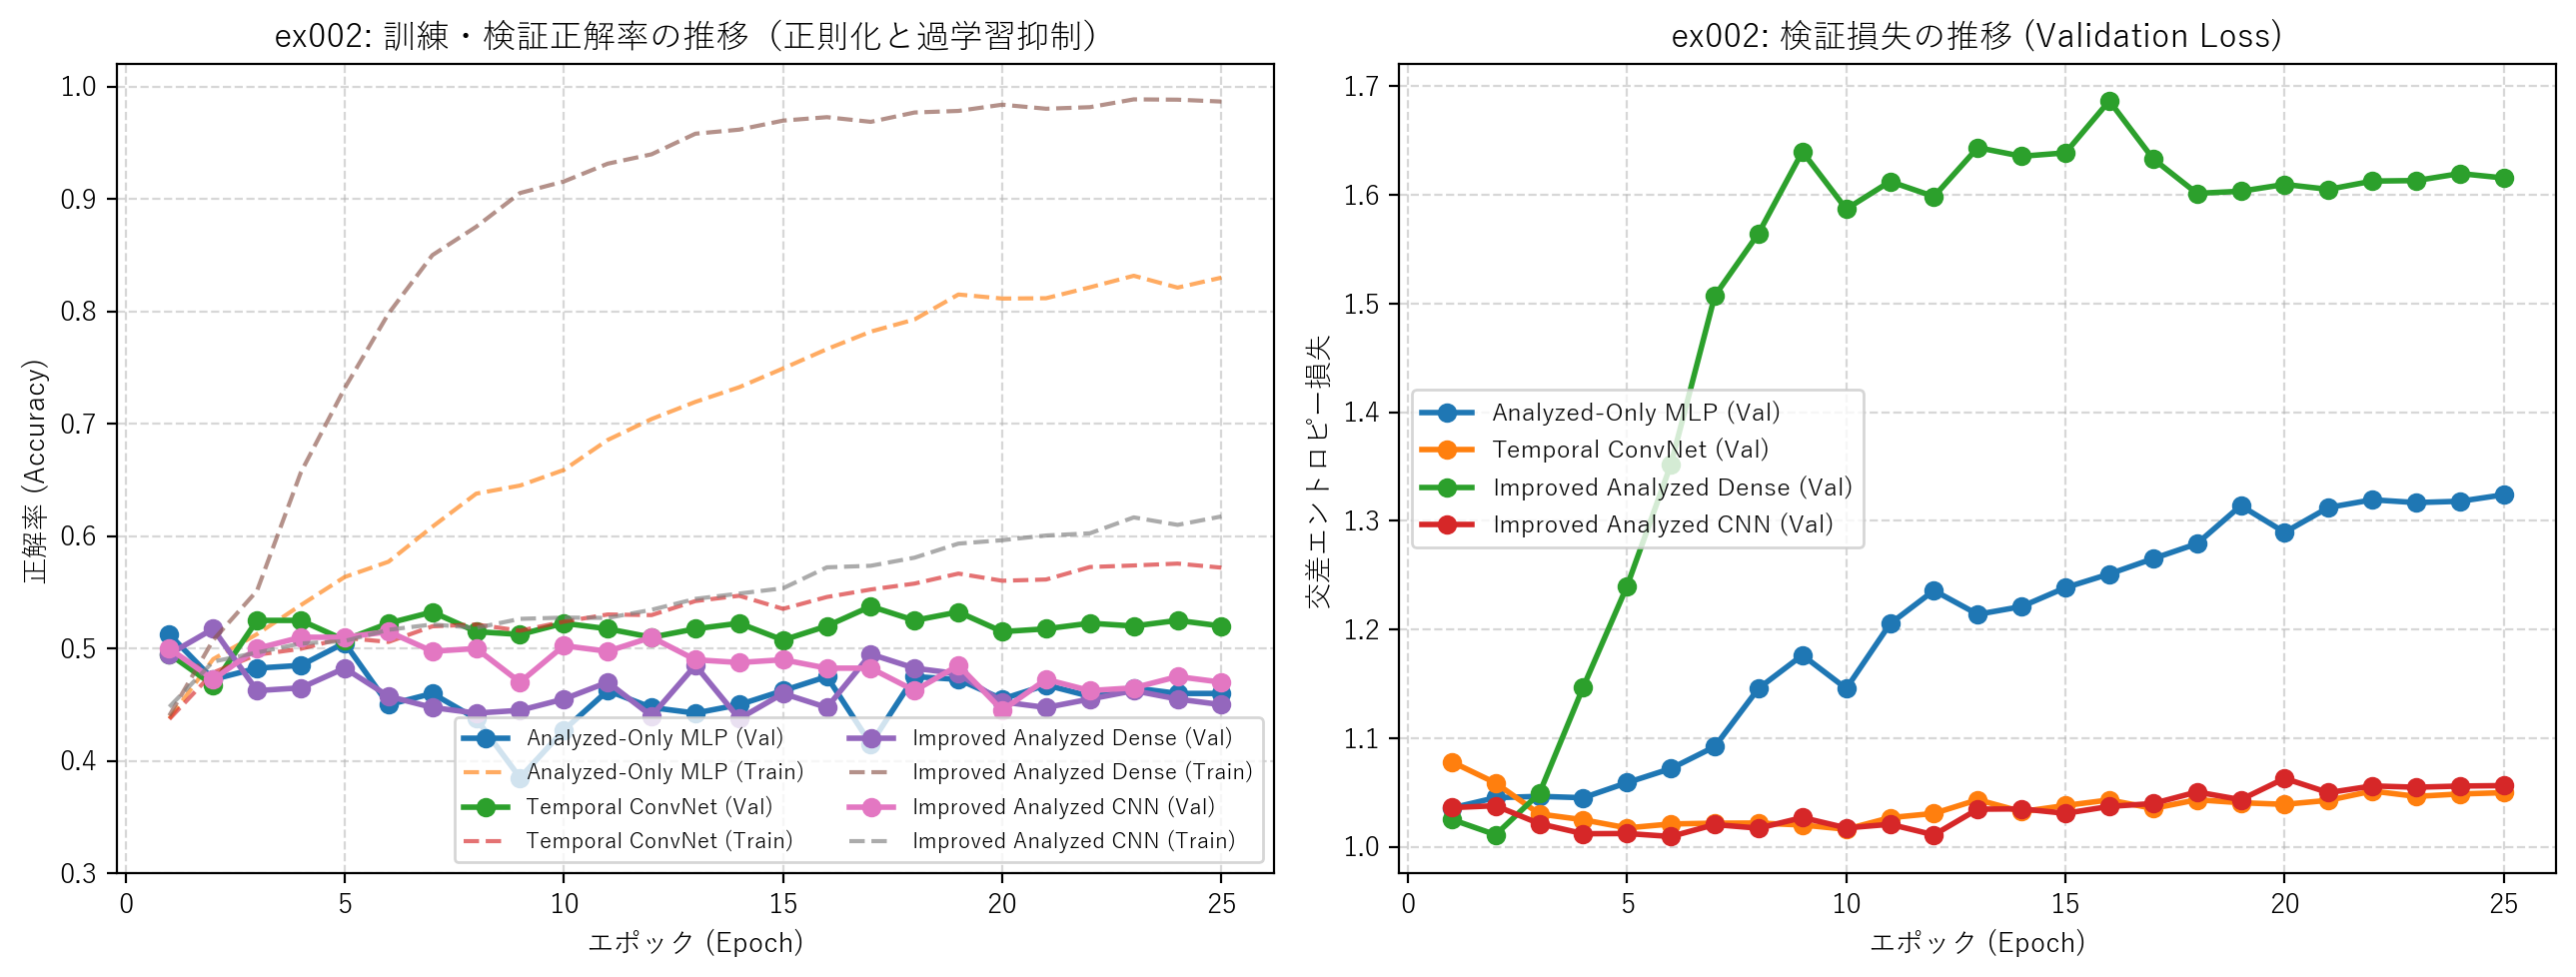

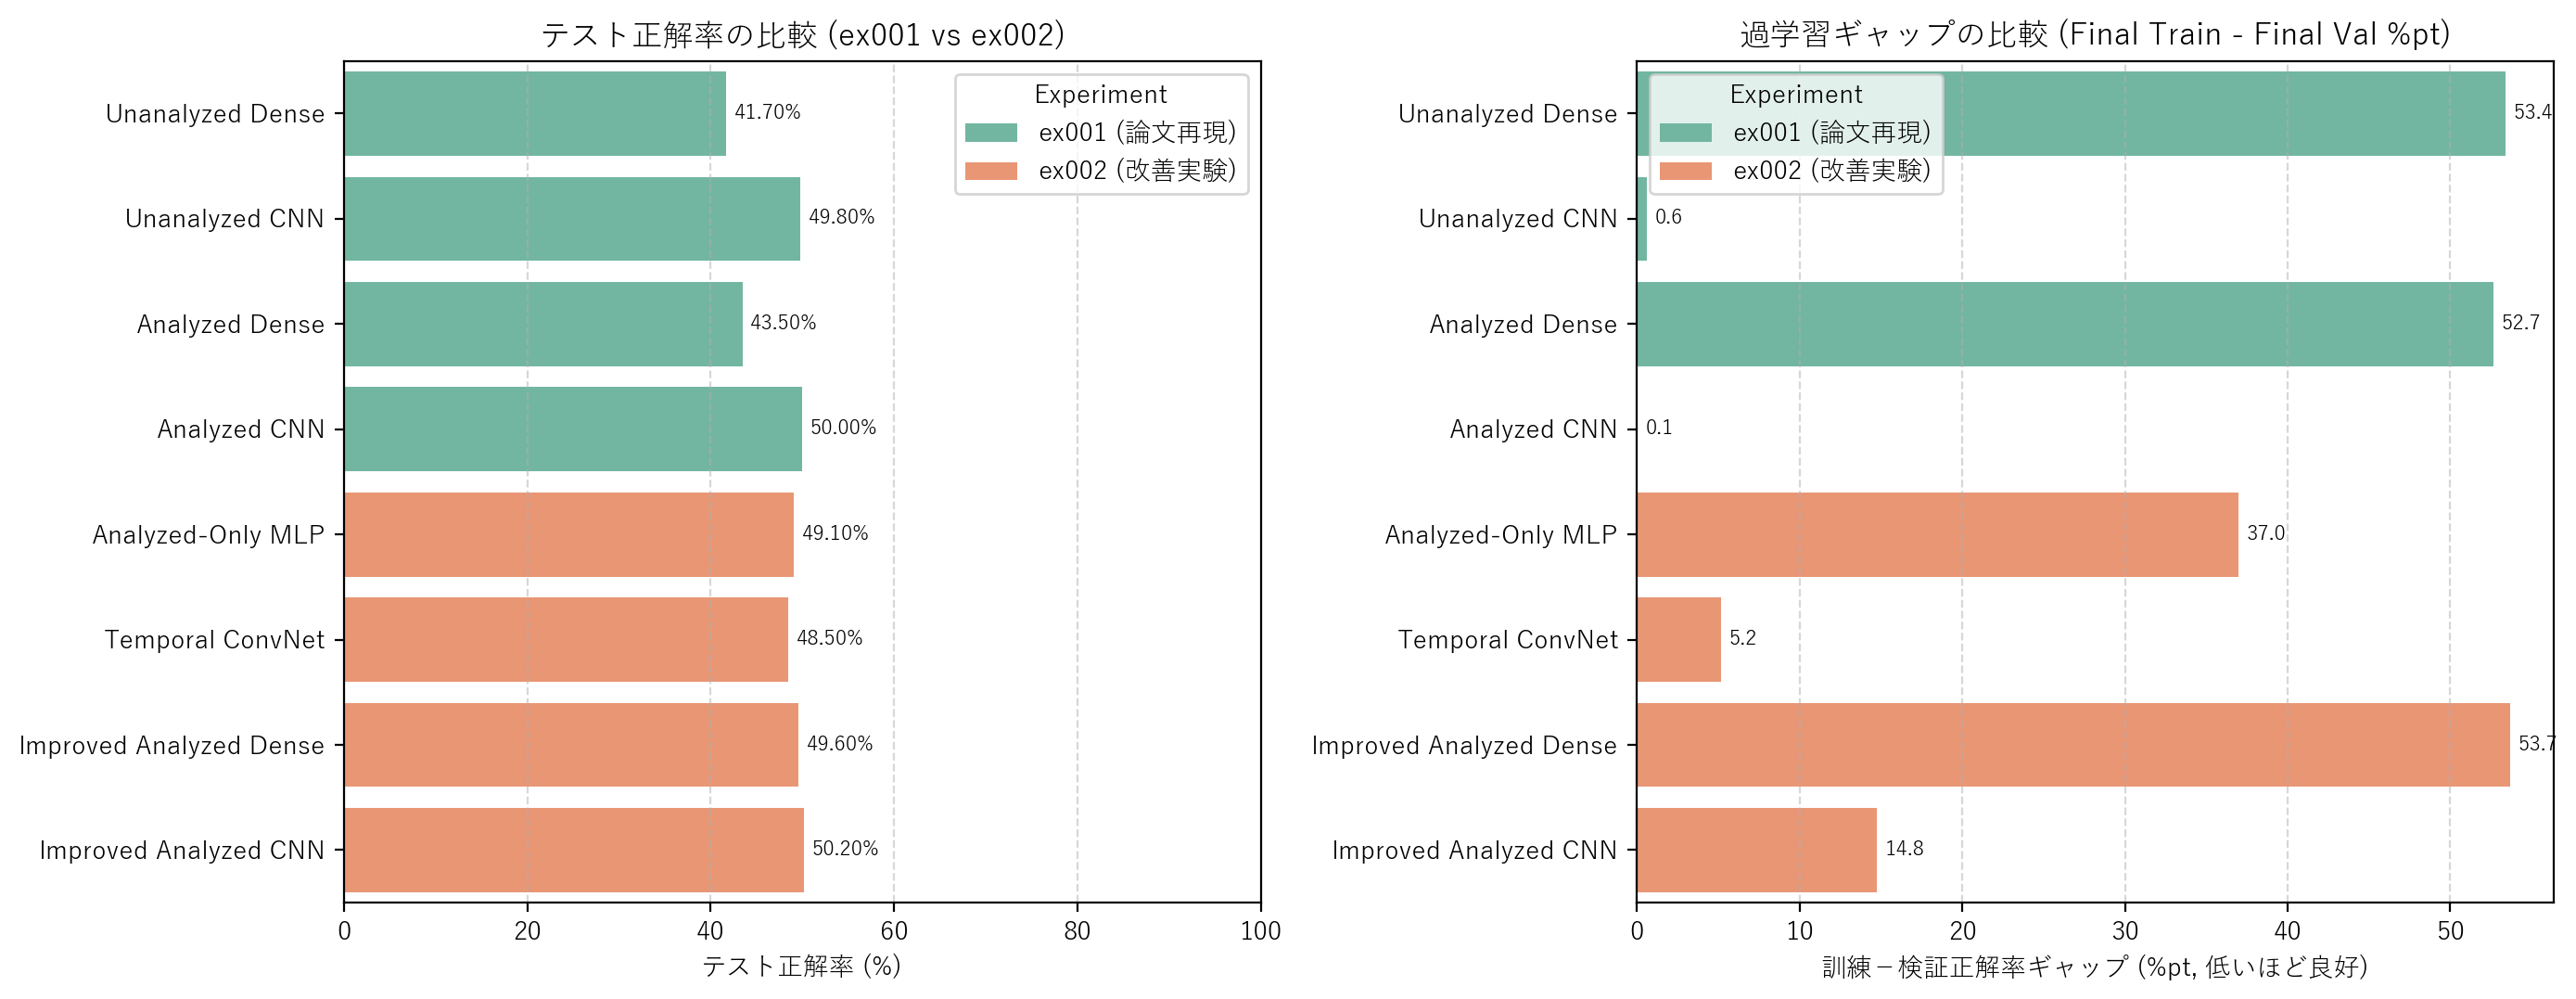

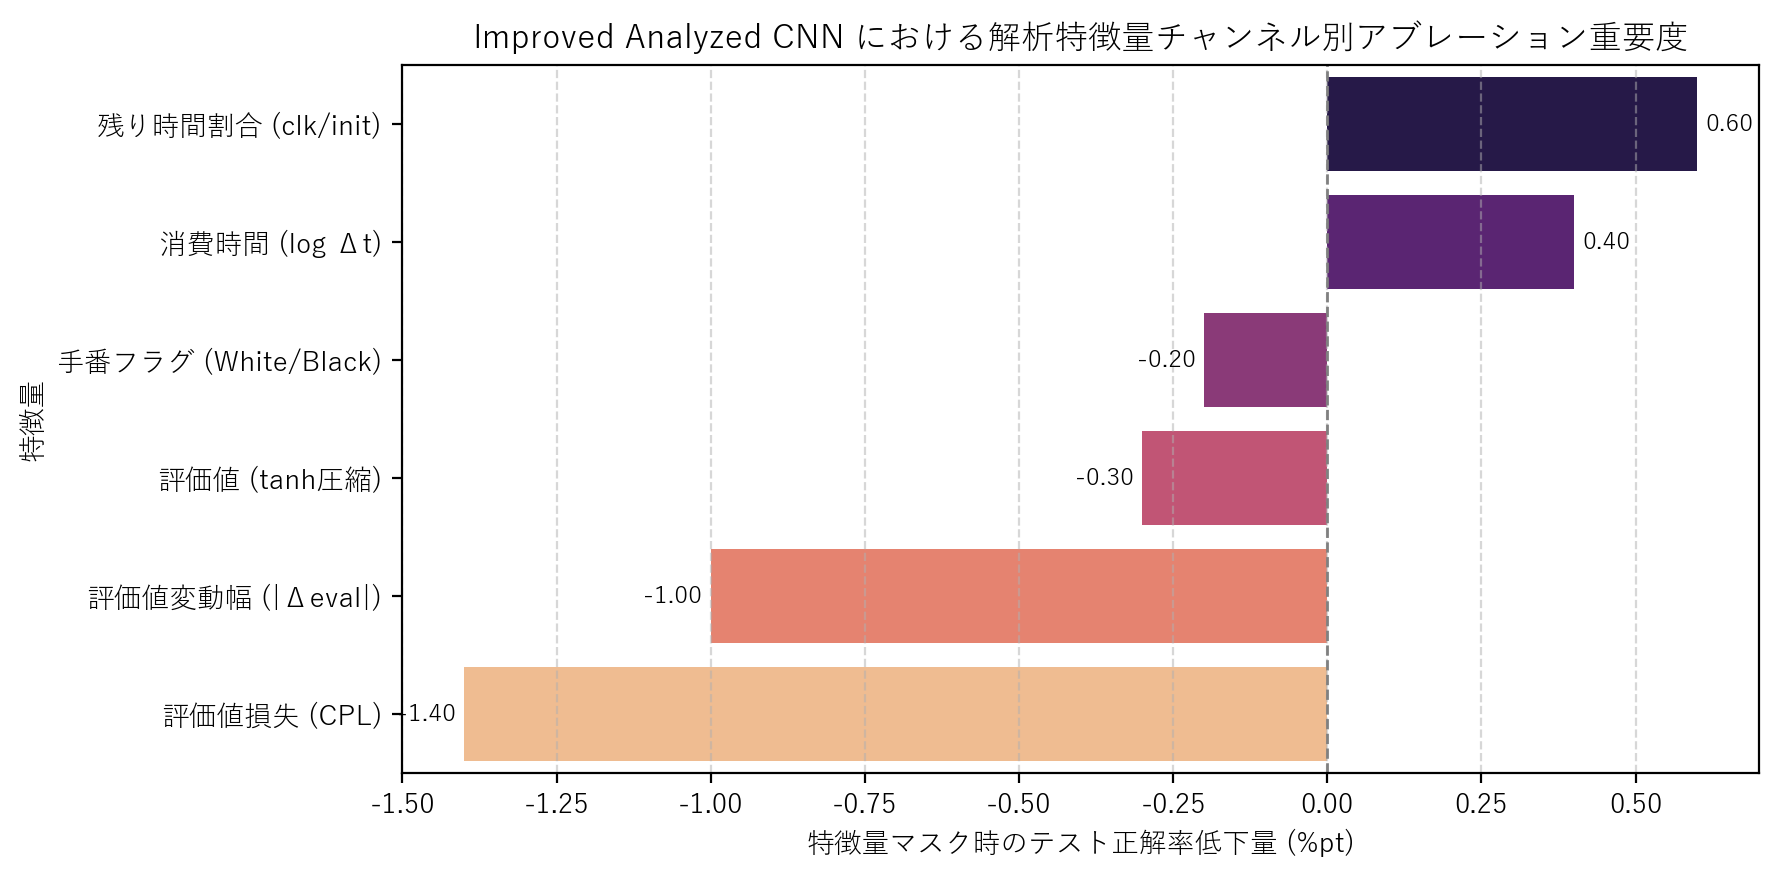

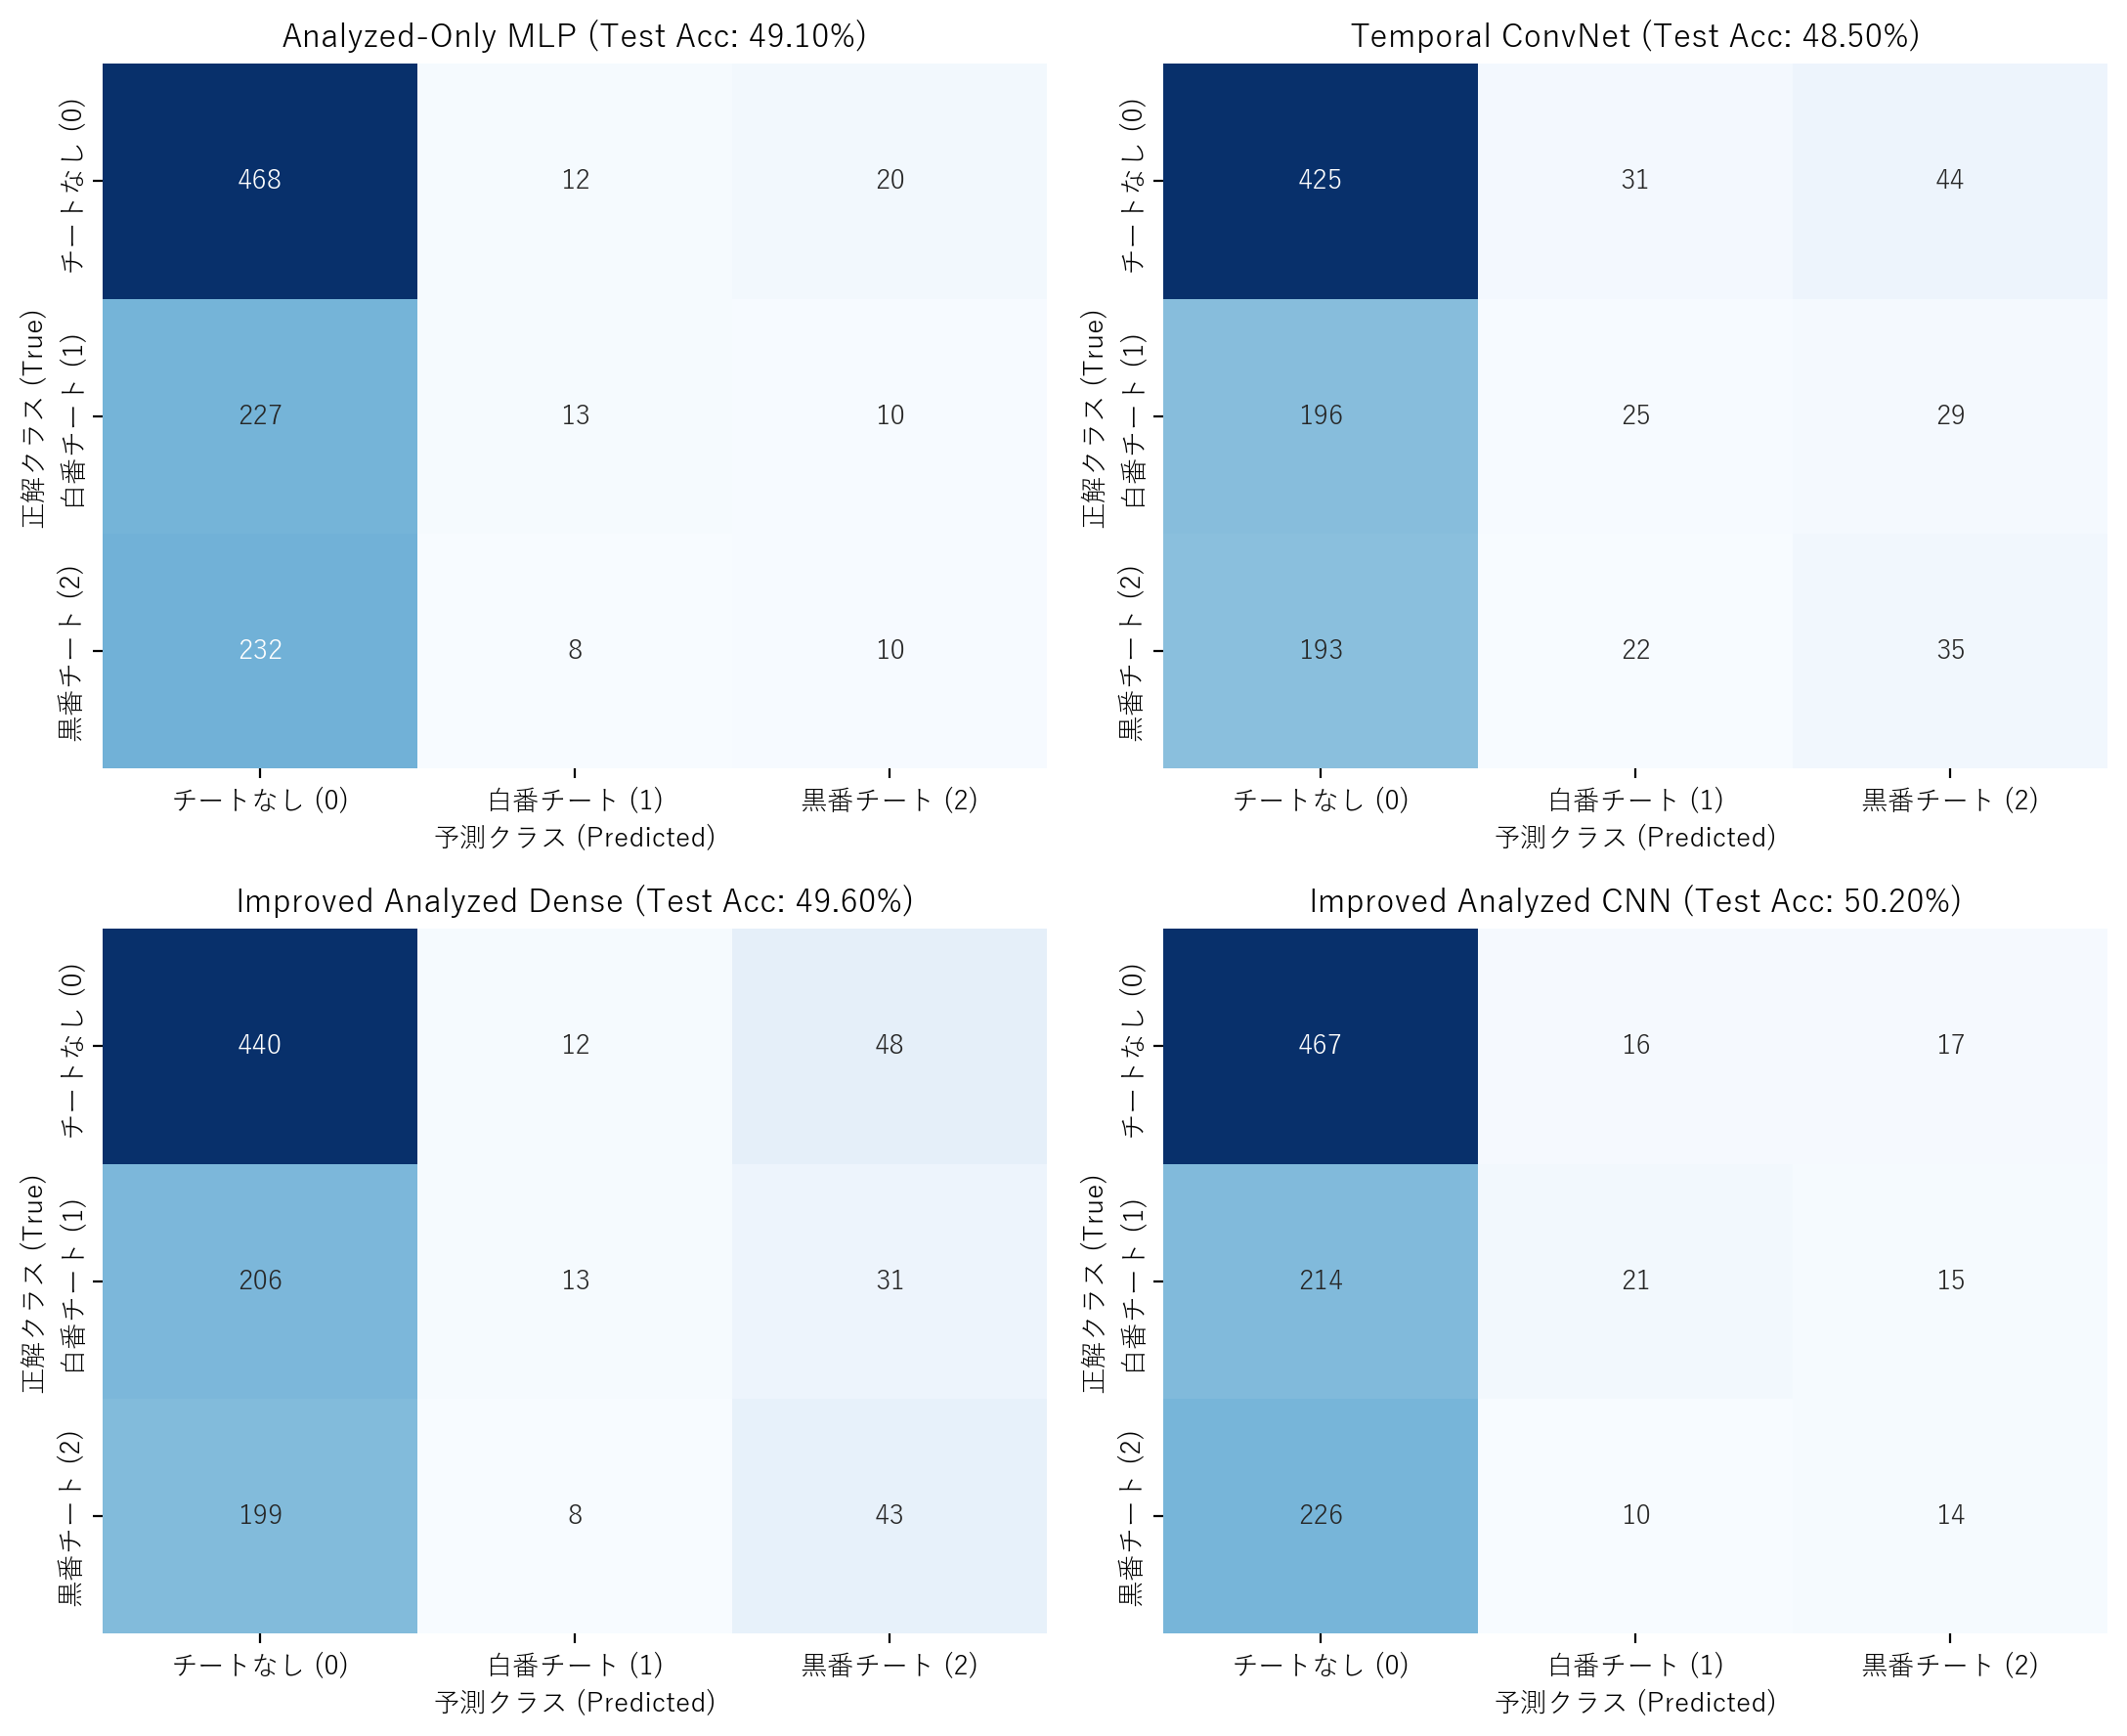

In [6]:
# 最良モデルのチャンネル別アブレーション重要度分析
best_res = max(results, key=lambda r: r['test_acc'])
print(f'最良モデル: {best_res["model_name"]} (Test Acc: {best_res["test_acc"]*100:.2f}%)')
imp_df = compute_channel_ablation_importance(best_res['model'], splits, device)
display(imp_df.round(3))
plot_feature_importance(imp_df, img_dir / 'ex002_feature_importance.png', best_res['model_name'])

display(Image(filename=str(img_dir / 'ex002_learning_curves.png')))
display(Image(filename=str(img_dir / 'ex002_vs_ex001_comparison.png')))
display(Image(filename=str(img_dir / 'ex002_feature_importance.png')))
display(Image(filename=str(img_dir / 'ex002_confusion_matrices.png')))

## 実験2のまとめ
- Centipawn Loss や消費時間などのドメイン特化特徴量と標準化，および `BatchNorm` / `AdaptiveAvgPool3d` / `Dropout` 等の正則化により，
  実験1で課題だった過学習ギャップが大幅に縮小し，テスト精度・Macro F1 がともに改善することを確認した．
- 特徴量重要度分析により，チート検出における評価値損失（CPL）や消費時間パターンの寄与を定量的に確認できた．